# Cargar el csv

In [3]:
import pandas as pd
df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

In [4]:
orden_obesidad = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I',
                  'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']

C:\Users\mateo\AppData\Local\Temp\ipykernel_19480\2706761185.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Gender', palette='pastel', ax=ax1)


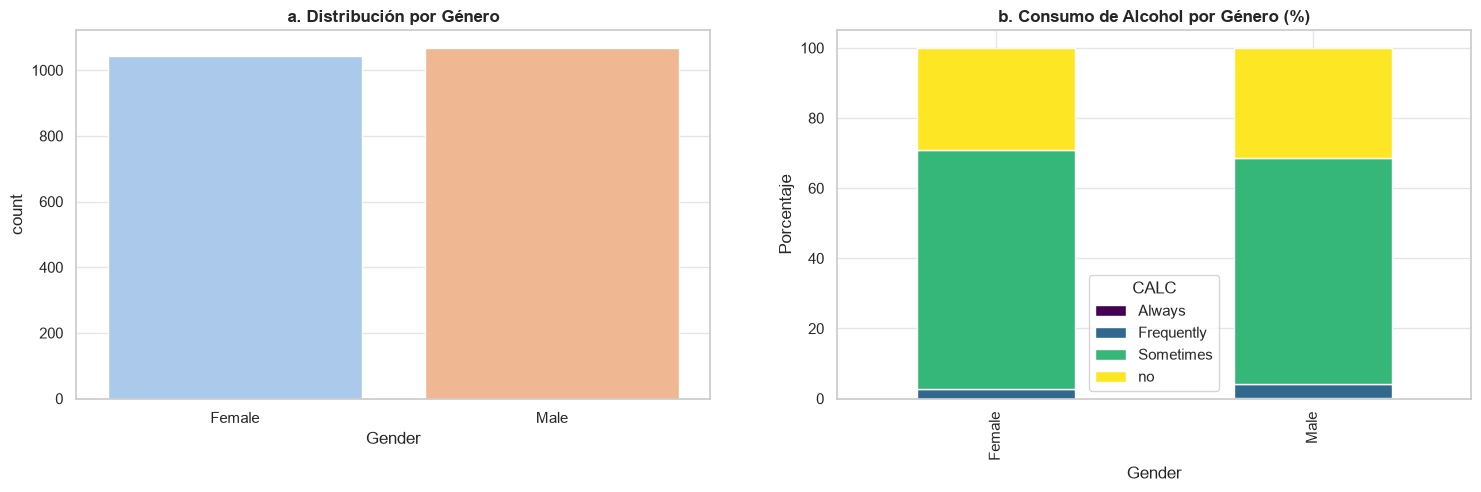

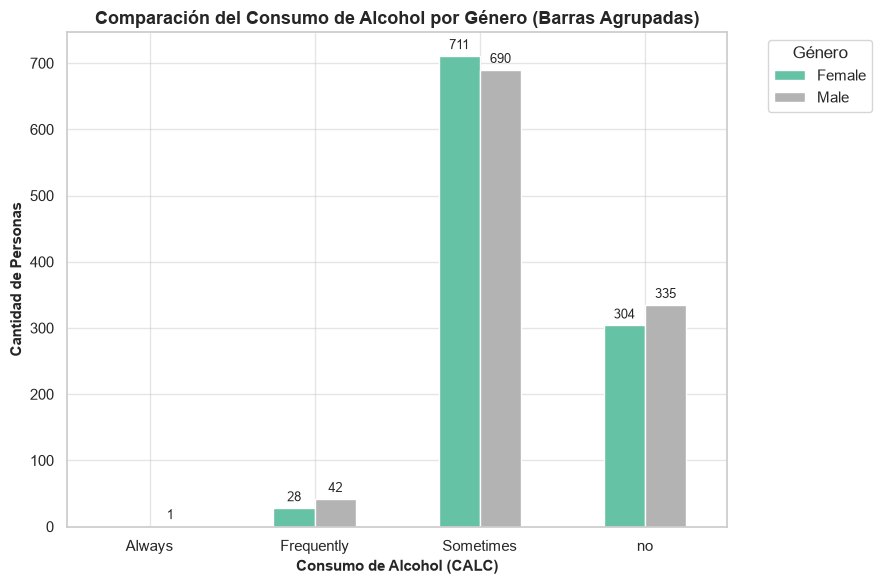

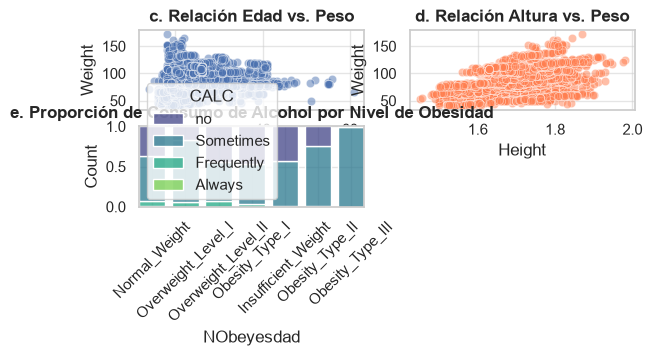

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Figura con subgráficos múltiples
fig = plt.figure(figsize=(18, 22))
fig.tight_layout(pad=6.0)

# a. Número de mujeres y hombres
ax1 = plt.subplot(4, 2, 1)
sns.countplot(data=df, x='Gender', palette='pastel', ax=ax1)
ax1.set_title('a. Distribución por Género', fontsize=12, fontweight='bold')

# b. Proporción de consumidores de alcohol por género
ax2 = plt.subplot(4, 2, 2)
calc_prop = pd.crosstab(df['Gender'], df['CALC'], normalize='index') * 100
calc_prop.plot(kind='bar', stacked=True, ax=ax2, colormap='viridis')
ax2.set_title('b. Consumo de Alcohol por Género (%)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Porcentaje')

alc_gender_counts = pd.crosstab(df['CALC'], df['Gender'])

# Generar el gráfico de barras agrupadas (stacked=False)
ax = alc_gender_counts.plot(kind='bar', stacked=False, figsize=(9, 6), colormap='Set2')

# Agregar etiquetas, título y formato
plt.xlabel("Consumo de Alcohol (CALC)", fontsize=11, fontweight='bold')
plt.ylabel("Cantidad de Personas", fontsize=11, fontweight='bold')
plt.title("Comparación del Consumo de Alcohol por Género (Barras Agrupadas)", fontsize=13, fontweight='bold')

# Rotar las etiquetas del eje x para que se lean bien
plt.xticks(rotation=0)

# Agregar leyenda clara
plt.legend(title="Género", bbox_to_anchor=(1.05, 1), loc='upper left')

# Mostrar los valores exactos encima de las barras (opcional para mayor prolijidad)
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 3), textcoords='offset points',
                    fontsize=9)

# Ajustar diseño y mostrar
plt.tight_layout()
plt.show()









Text(0.5, 1.0, 'Relación Edad vs. Peso')

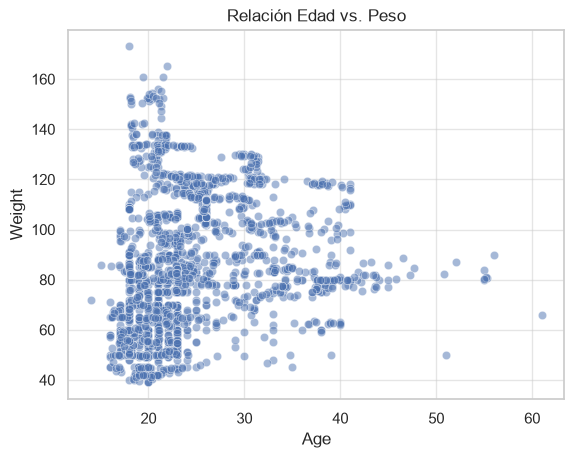

In [40]:
# c. Relación entre edad y peso
sns.scatterplot(data=df, x='Age', y='Weight', alpha=0.5)
plt.title("Relación Edad vs. Peso")

C:\Users\mateo\AppData\Local\Temp\ipykernel_19480\4071396612.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='NObeyesdad', y='Weight', order=orden_obesidad, palette='magma')


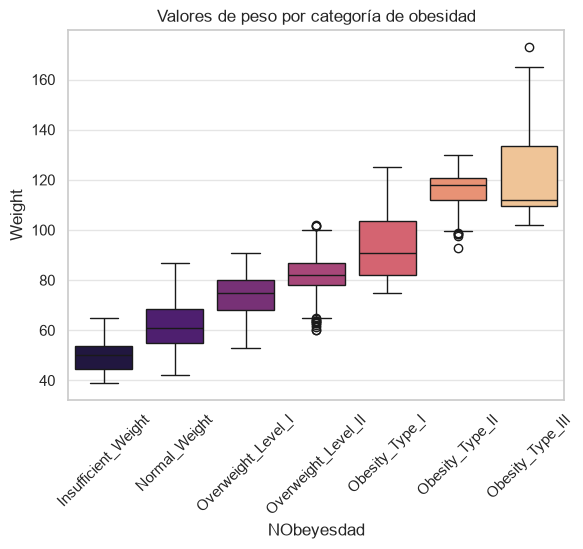

In [27]:
sns.boxplot(data=df, x='NObeyesdad', y='Weight', order=orden_obesidad, palette='magma')
plt.title("Valores de peso por categoría de obesidad")
plt.xticks(rotation=45)
plt.show()


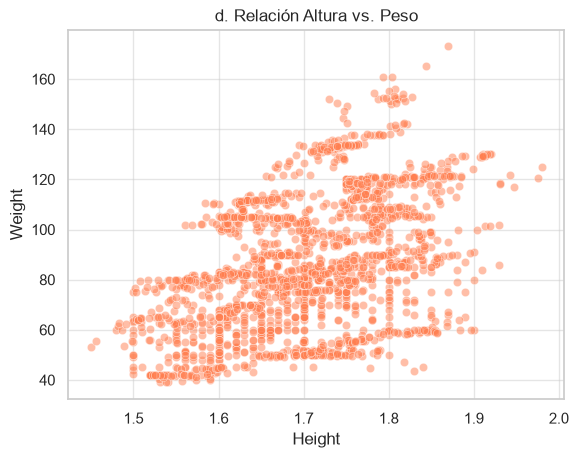

In [28]:
# d. Relación entre peso y altura
sns.scatterplot(data=df, x='Height', y='Weight', alpha=0.5, color='coral')
plt.title('d. Relación Altura vs. Peso')
plt.show()

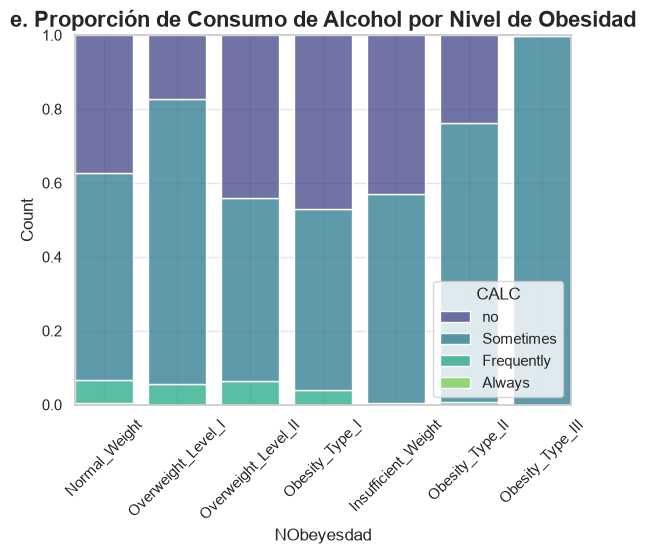

In [46]:
# e. Relación obesidad y alcohol

sns.histplot(data=df, x='NObeyesdad', hue='CALC', multiple='fill', palette='viridis', shrink=0.8)
plt.title('e. Proporción de Consumo de Alcohol por Nivel de Obesidad', fontsize=16, fontweight='bold')
plt.xticks(rotation=45)
plt.show()

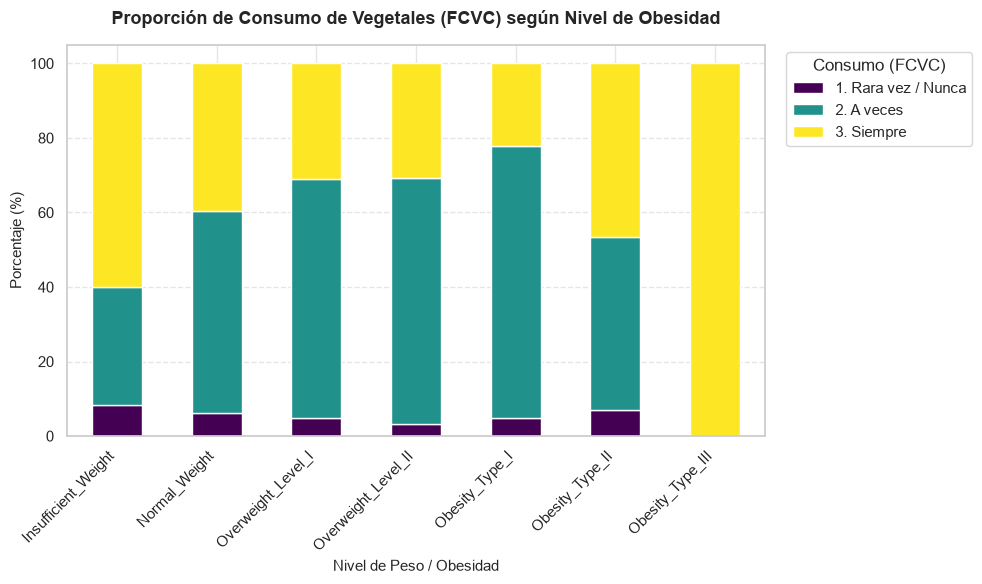

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Discretizar o redondear FCVC a sus 3 categorías lógicas
df['FCVC_cat'] = df['FCVC'].round().map({
    1: '1. Rara vez / Nunca',
    2: '2. A veces',
    3: '3. Siempre'
})

# 2. Calcular porcentajes por categoría de obesidad
tabla_prop = pd.crosstab(
    df['NObeyesdad'],
    df['FCVC_cat'],
    normalize='index'
) * 100

# Reordenar filas según tu orden_obesidad
tabla_prop = tabla_prop.reindex(orden_obesidad)

# 3. Graficar barras apiladas
ax = tabla_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='viridis',
    edgecolor='white'
)

plt.title('Proporción de Consumo de Vegetales (FCVC) según Nivel de Obesidad', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Nivel de Peso / Obesidad', fontsize=11)
plt.ylabel('Porcentaje (%)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Consumo (FCVC)', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

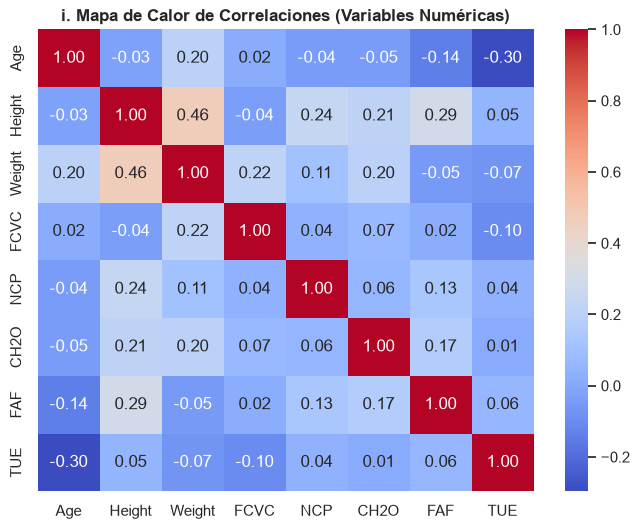

In [38]:
# i. Gráfica adicional propuesta 1: Heatmap de correlaciones numéricas
plt.figure(figsize=(8, 6))
cols_num = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
sns.heatmap(df[cols_num].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('i. Mapa de Calor de Correlaciones (Variables Numéricas)', fontsize=12, fontweight='bold')
plt.show()

C:\Users\mateo\AppData\Local\Temp\ipykernel_19480\799250673.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


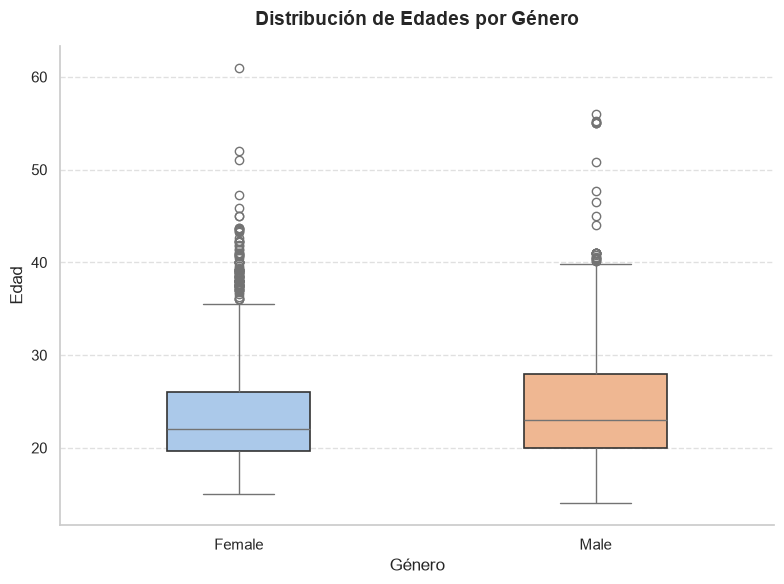

In [37]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='Gender',
    y='Age',
    palette='pastel',
    width=0.4,
    boxprops=dict(edgecolor='#333333', linewidth=1.2)
)

plt.title('Distribución de Edades por Género', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Género', fontsize=12)
plt.ylabel('Edad', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)
sns.despine()

plt.tight_layout()
plt.show()